# 量子生物 · 四残基格点构象与接触能

QuantumBridge / 科学计算 / 中文可执行案例

**执行状态：仅本地运行；未提交夸父真机；新增云任务 0。**

面向了解 Python 的读者：完成建模、检查中间结果、运行原生电路或明确标记的经典密码步骤，并与独立基线核对。

**范围边界：** 这是粗粒度 HP 风格教学模型，非真实原子结构、蛋白预测、药物构象筛选或生物活性验证；没有使用患者或药物数据。

## 1. 原理与计算对象

使用 HHHH 四个疏水残基的二维方格链，固定第一条键方向以消除整体旋转自由度。剩下两次转向各用两比特编码：00 左转、01 直行、10 右转，11 为非法码。
非相邻残基 0 与 3 相距一个格点时接触能为 -1。代价 $C(x)=-contact_{03}+5\,violations$，违反项包括非法编码和链重叠。完整枚举 16 个串独立给出最优构象基线。

将代价真值表用 Walsh 展开写成 $H_C=\sum_S c_S\prod_{i\in S}Z_i$。本例允许三、四体项，**不是声称所有构象都已转成二次 QUBO**。一层 QAOA 为 $e^{-i\beta\sum X}e^{-i\gamma H_C}|+\rangle^{\otimes4}$。Z 项相互对易，成本演化无 Trotter 分裂误差；一层表达能力仍有限。

## 2. 实现步骤

1. 枚举两次转向，重建每个候选的四个坐标。
2. 检查链自交、编码有效性及非键接触；输出所有候选表。
3. 展开对角代价并检查罚函数最小值可行。
4. 本地理想态搜索 QAOA 参数，记录接受的改进。
5. 采样、筛选实际观测到的可行构象，报告能量差与可行率；绘制折叠形状。

## 3. 环境与可复现参数

依赖本仓库、NumPy、Matplotlib、Jupyter；安全案例还使用已安装的 OpenSSL / cryptography。模型和电路不调用 Qiskit 或 PennyLane。Notebook 保留真实执行输出，Python 解释器版本会在下方打印。

In [1]:
import os, sys, json
get_ipython().run_line_magic('matplotlib', 'inline')
from pathlib import Path
root = next((p for p in [Path(os.environ.get("QB_REPO_ROOT", ".")).resolve(), *Path.cwd().resolve().parents] if (p/"quantumbridge").is_dir() and (p/"scripts").is_dir()), None)
if root is None:
    raise RuntimeError("Run from the QuantumBridge checkout or set QB_REPO_ROOT.")
sys.path.insert(0, str(root)); sys.path.insert(0, str(root/"scripts"))
from IPython.display import display, HTML
from application_notebook_support import STYLE, show_json, intermediate_tables, plot_intermediate, show_measurements
from quantumbridge.applications.common import run_local_case
display(HTML(STYLE))
SHOTS, SEED = 1024, 20261023
print("Execution: LOCAL ONLY | cloud submissions: 0 | shots per circuit:", SHOTS)

print(sys.version)
import numpy as np
from quantumbridge.core import Circuit
from quantumbridge.devices import StatevectorDevice
from quantumbridge.chemistry import Molecule, molecular_hamiltonian_native
from quantumbridge.chemistry.excitations import apply_fermionic_excitation
from quantumbridge.chemistry.fermion import FermionicOp
from quantumbridge.chemistry.mappings import JordanWignerMapper
from quantumbridge.finance.kernels import labels, prepare_real_state
from quantumbridge.utils.math import PauliString
from quantumbridge.applications.common import ApplicationCase, optimization_case

Execution: LOCAL ONLY | cloud submissions: 0 | shots per circuit: 1024
3.12.6 (v3.12.6:a4a2d2b0d85, Sep  6 2024, 16:08:03) [Clang 13.0.0 (clang-1300.0.29.30)]


## 4. 完整应用建模代码

以下是本案例实际执行的应用函数，不是伪代码。底层电路、映射、演化与采样复用仓库原生接口；优化类的共享辅助函数也位于 `quantumbridge/applications/common.py`。

In [2]:
def biomedicine_case():
    """A four-residue hydrophobic square-lattice research model, not a drug predictor."""
    candidates = []
    turns = {0: 1, 1: 0, 2: -1}
    steps = [(1, 0), (0, 1), (-1, 0), (0, -1)]
    for bits in labels(4):
        codes = [int(bits[:2], 2), int(bits[2:], 2)]
        valid_codes = all(code in turns for code in codes)
        points, heading = [(0, 0), (1, 0)], 0
        if valid_codes:
            for code in codes:
                heading = (heading + turns[code]) % 4
                dx, dy = steps[heading]
                points.append((points[-1][0] + dx, points[-1][1] + dy))
        overlaps = len(points) - len(set(points))
        contact = int(
            valid_codes
            and abs(points[0][0] - points[-1][0]) + abs(points[0][1] - points[-1][1])
            == 1
        )
        violation = sum(code not in turns for code in codes) + overlaps
        candidates.append(
            {
                "bitstring": bits,
                "turn_codes": codes,
                "coordinates": points,
                "contact_0_3": contact,
                "violations": violation,
                "feasible": violation == 0,
                "objective": -contact,
                "penalized_cost": -contact + 5 * violation,
            }
        )
    return optimization_case(
        "biomedicine",
        "science",
        "Four-residue lattice conformation and contact energy",
        {
            "sequence": "HHHH",
            "residues": 4,
            "first_bond": "fixed along +x",
            "turn_encoding": {
                "00": "left",
                "01": "straight",
                "10": "right",
                "11": "invalid",
            },
            "contact_energy": -1,
            "penalty": 5,
            "data_source": "explicit coarse-grained synthetic model, not atomic coordinates or drug data",
        },
        candidates,
    )


In [3]:
case = biomedicine_case()
show_json(case.inputs)

## 5. 中间结果与效果

下方完整列出模型候选、优化轨迹或物理中间量。图中的 exact / classical 是经典计算基线，不冒充量子实验。图表使用英文坐标避免本机中文字体缺失，解释与表格保留中文。

bitstring,turn_codes,coordinates,contact_0_3,violations,feasible,objective,penalized_cost
0000,"[0, 0]","[[0, 0], [1, 0], [1, 1], [0, 1]]",1,0,True,-1,-1
0001,"[0, 1]","[[0, 0], [1, 0], [1, 1], [1, 2]]",0,0,True,0,0
0010,"[0, 2]","[[0, 0], [1, 0], [1, 1], [2, 1]]",0,0,True,0,0
0011,"[0, 3]","[[0, 0], [1, 0]]",0,1,False,0,5
0100,"[1, 0]","[[0, 0], [1, 0], [2, 0], [2, 1]]",0,0,True,0,0
0101,"[1, 1]","[[0, 0], [1, 0], [2, 0], [3, 0]]",0,0,True,0,0
0110,"[1, 2]","[[0, 0], [1, 0], [2, 0], [2, -1]]",0,0,True,0,0
0111,"[1, 3]","[[0, 0], [1, 0]]",0,1,False,0,5
1000,"[2, 0]","[[0, 0], [1, 0], [1, -1], [2, -1]]",0,0,True,0,0
1001,"[2, 1]","[[0, 0], [1, 0], [1, -1], [1, -2]]",0,0,True,0,0


improvement,expected_penalized_cost,gamma,beta
0,2.375,0,0
1,2.375,0,1.9332878
2,2.3504091,0.78539816,1.6916268
3,2.1941387,0.78539816,1.9332878
4,1.825802,0.78539816,2.1749488
5,1.3950476,0.78539816,2.4166097
6,1.2242447,0.78539816,2.6582707
7,0.6956637,1.5707963,2.4166097
8,0.3352652,1.5707963,2.6582707
9,-0.17488316,2.3561945,2.6582707


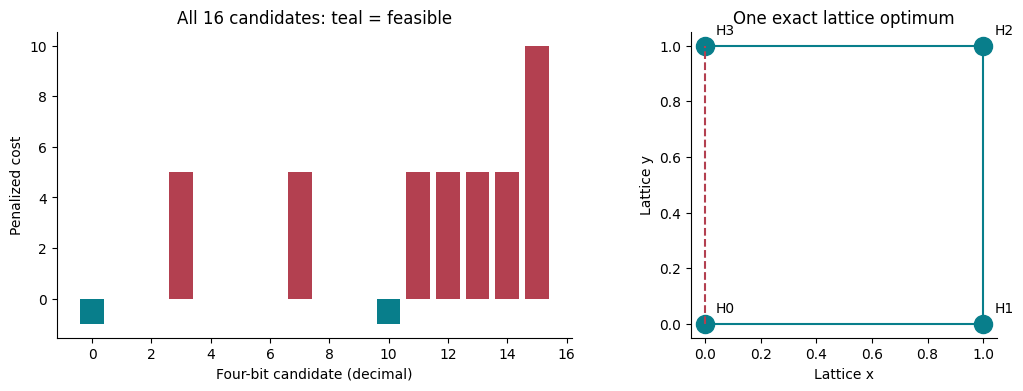

In [4]:
intermediate_tables(case)
plot_intermediate(case)

## 6. 实际运行与最终效果

模拟器使用固定种子逐次采样，counts 总数必须等于 shots。估计标准误由实际样本方差计算；近似 95% 区间可写作 estimate ± 1.96 × SE，但小样本及零计数需另用适当区间。本例不把这些区间当成硬件精度验收。

experiment,qubits,gates,shots,seed
qaoa,4,43,1024,20261023


observable,estimate,standard_error,ideal_reference
qaoa,-0.28808594,0.017749201,-0.27570852


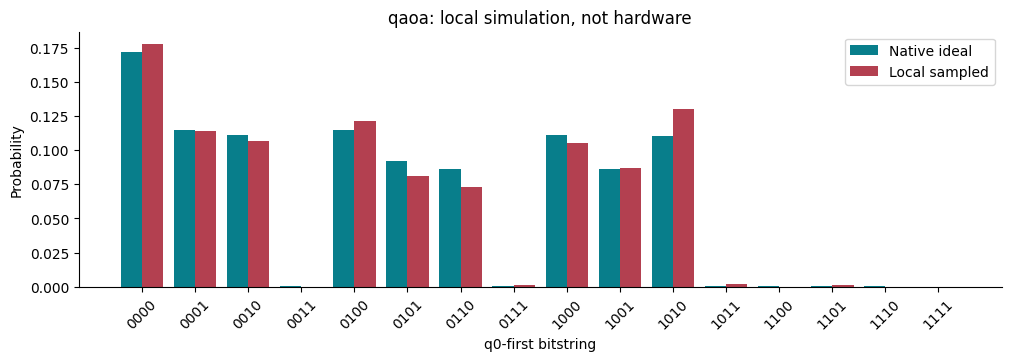

experiment,counts
qaoa,"{""0010"": 109, ""0101"": 83, ""1010"": 133, ""0001"": 117, ""0000"": 182, ""1001"": 89, ""1000"": 108, ""0100"": 124, ""0110"": 75, ""1101"": 1, ""1011"": 2, ""0111"": 1}"


In [5]:
evidence = run_local_case(case, shots=SHOTS, seed=SEED)
show_measurements(case, evidence)

## 7. 可检查的电路输出

导出全部业务电路的 OpenQASM 2，位串采用 q0-first。可导出不等于已通过夸父设备门集、耦合图、深度和精度验收；本批不会访问凭据、提交任务或消耗金融额度。纯经典案例没有伪造量子电路。

In [6]:
for name, result in evidence['experiments'].items():
    print('\n---', name, '---\n'+result['openqasm2'])
if not evidence['experiments']:
    print('Classical cryptography / security workflow: no quantum circuit.')


--- qaoa ---
OPENQASM 2.0;
include "qelib1.inc";
qreg q[4];
creg c[4];
h q[0];
h q[1];
h q[2];
h q[3];
cx q[0],q[1];
cx q[1],q[2];
cx q[2],q[3];
rz(-0.065149833036131602) q[3];
cx q[2],q[3];
cx q[1],q[2];
cx q[0],q[1];
cx q[0],q[1];
cx q[1],q[2];
rz(-0.065149833036131671) q[2];
cx q[1],q[2];
cx q[0],q[1];
cx q[0],q[1];
rz(0.65149833036131655) q[1];
cx q[0],q[1];
cx q[0],q[2];
cx q[2],q[3];
rz(-0.065149833036131713) q[3];
cx q[2],q[3];
cx q[0],q[2];
cx q[0],q[2];
rz(-0.065149833036131602) q[2];
cx q[0],q[2];
rz(-0.65149833036131644) q[0];
cx q[1],q[3];
rz(-0.065149833036131602) q[3];
cx q[1],q[3];
rz(-0.71664816339744819) q[1];
cx q[2],q[3];
rz(0.65149833036131644) q[3];
cx q[2],q[3];
rz(-0.65149833036131644) q[2];
rz(-0.71664816339744819) q[3];
rz(1.7590454919755543) q[0];
u1(-1.7590454919755543) q[0];
rx(5.366541413767342) q[0];
rx(5.366541413767342) q[1];
rx(5.366541413767342) q[2];
rx(5.366541413767342) q[3];
measure q[0] -> c[0];
measure q[1] -> c[1];
measure q[2] -> c[2];
measure

## 8. 结果解释、复做与非目标

best_observed_feasible 只从实际采到的可行串中选择。optimal_probability 是最优串的采样总频率，不等同于真实蛋白折叠成功率。

这是粗粒度 HP 风格教学模型，非真实原子结构、蛋白预测、药物构象筛选或生物活性验证；没有使用患者或药物数据。

练习：对已有电路将 shots 改为 2048，比较估计与标准误；如果是纯经典密码案例，比较密文/公钥大小和篡改检测结果。安全案例的私钥只在临时目录或内存中存在，不输出密钥。重新执行此 Notebook 仍然只运行本地代码。

In [7]:
repeat = run_local_case(case, shots=2048, seed=SEED+100)
show_json({'execution_mode':repeat['execution_mode'], 'estimates':repeat['estimates'], 'new_cloud_tasks':repeat['new_cloud_tasks']})
assert all(sum(row['counts'].values()) == 2048 for row in repeat['experiments'].values())
assert repeat['new_cloud_tasks'] == 0
assert repeat['hardware_access'] is False

In [8]:
artifact = {'inputs':case.inputs, 'intermediate':case.intermediate, 'reference':case.reference, 'evidence':evidence}
path = root/'output/jupyter-notebook/science/02_biomedicine_evidence.json'
path.parent.mkdir(parents=True, exist_ok=True)
path.write_text(json.dumps(artifact, ensure_ascii=False, indent=2), encoding='utf-8')
print('Evidence:', path.name)

Evidence: 02_biomedicine_evidence.json


## 9. 参考与责任边界

独立编写应用代码，未复制上游 SDK 实现或第三方教程代码；下列资料用于数学与接口背景。

- [二维 HP 格点模型研究](https://arxiv.org/abs/1608.05855)

本案例不是生产支持证书，也不代表 Qiskit / PennyLane 全量替代已经完成。